In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# **Task 1 – Data Exploration & Preprocessing**

In [4]:
df=pd.read_excel("https://github.com/GeethaGunasekaran1/Dataset_rep/raw/refs/heads/main/mall_customer_spend.xlsx")

In [5]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [8]:
df.shape

(200, 5)

In [9]:
df.isna().sum()

,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [10]:
df.rename(columns={'Annual Income (k$)':'Annual Income','Spending Score (1-100)':'Spending Score'},inplace=True)

In [13]:
df.head()

,CustomerID,Genre,Age,Annual Income,Spending Score
0,1,Male,19,0.000000,0.387755
1,2,Male,21,0.000000,0.816327
2,3,Female,20,0.008197,0.051020
3,4,Female,23,0.008197,0.775510
4,5,Female,31,0.016393,0.397959


In [12]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
df[['Annual Income','Spending Score']]=scaler.fit_transform(df[['Annual Income','Spending Score']])

In [14]:
df_2d=df[['Annual Income','Spending Score']]

In [15]:
df_2d.head()

,Annual Income,Spending Score
0,0.000000,0.387755
1,0.000000,0.816327
2,0.008197,0.051020
3,0.008197,0.775510
4,0.016393,0.397959


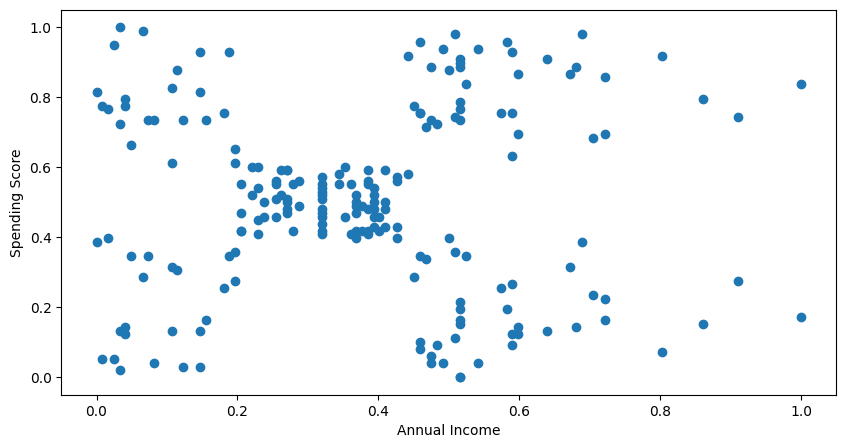

In [16]:
plt.figure(figsize=(10,5))
plt.scatter(df_2d['Annual Income'],df_2d['Spending Score'])
plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.show()

# Task 2 – K-Means Clustering

### KMeans clustering

In [18]:
from sklearn.cluster import KMeans
kmean=KMeans(n_clusters=5,random_state=42)
kmean.fit(df_2d)
labels_kmean=kmean.predict(df_2d)

In [20]:
labels_kmean

array([4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 0, 0,
       4, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 3, 1, 0, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 0, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1], dtype=int32)

In [21]:
kmean.cluster_centers_

array([[0.32695811, 0.49533888],
       [0.58638083, 0.82783883],
       [0.08792846, 0.79962894],
       [0.59631148, 0.16921769],
       [0.08792846, 0.19619666]])

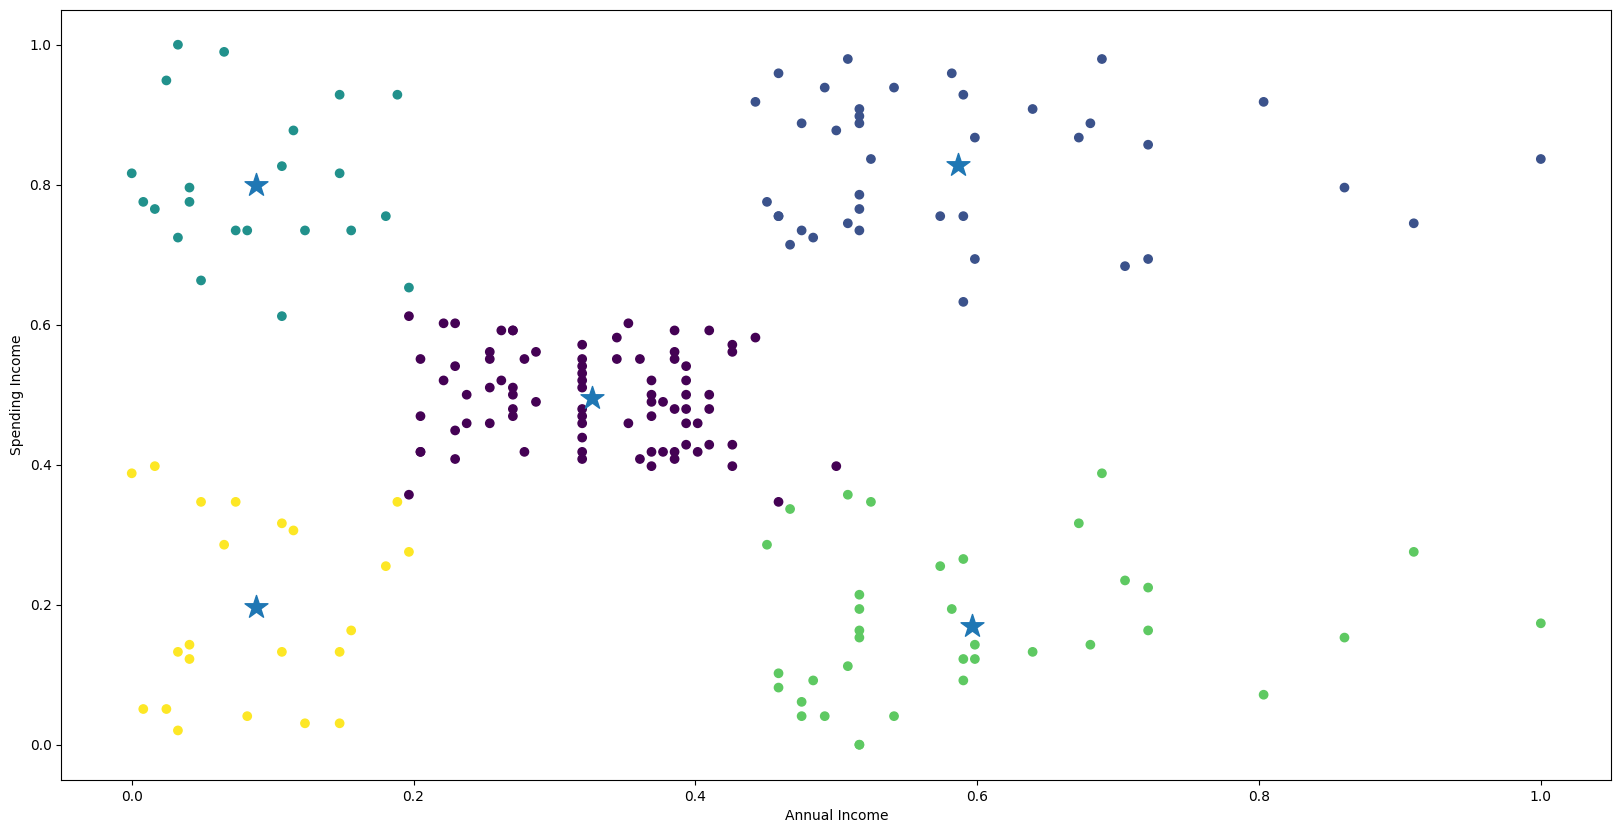

In [23]:
plt.figure(figsize=(20,10))
plt.scatter(df_2d['Annual Income'],df_2d['Spending Score'],c=labels_kmean)
plt.scatter(kmean.cluster_centers_[:,0],kmean.cluster_centers_[:,1],marker='*',s=300)
plt.xlabel('Annual Income')
plt.ylabel('Spending Income')
plt.show()

Roughly put a clusters using the scatter plot that time k=5

Elbow Methods


1.   WCSS
2.   Silhouette








In [28]:
wcss=[]
cluster=range(1,11)
for i in cluster:
  kmean_wcss=KMeans(n_clusters=i,random_state=42)
  kmean_wcss.fit(df_2d)
  wcss.append(kmean_wcss.inertia_)
wcss_kmean=pd.DataFrame({'K':cluster,'Wcss':wcss})
wcss_kmean

,K,Wcss
0,1,23.040720
1,2,14.085983
2,3,9.059793
3,4,6.121857
4,5,3.585167
5,6,3.223307
6,7,2.909542
7,8,2.469995
8,9,2.287402
9,10,1.867002


See this wcss values check the drop down value continous value may be k=5 is the best

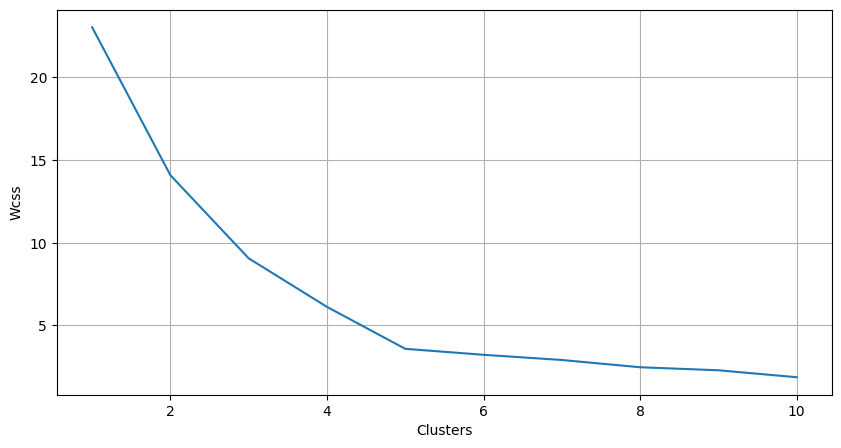

In [27]:
plt.figure(figsize=(10,5))
plt.plot(cluster,wcss)
plt.xlabel('Clusters')
plt.ylabel('Wcss')
plt.grid()
plt.show()

In [34]:
from sklearn.metrics import silhouette_score
sil_score=[]
cluster=range(2,11)
for i in cluster:
  kmean_sil=KMeans(n_clusters=i,random_state=42)
  kmean_sil.fit(df_2d)
  labels_sil=kmean_sil.predict(df_2d)
  sil_score.append(silhouette_score(df_2d,labels_sil))
sil=pd.DataFrame({'K':cluster,'Silhoutte Score':sil_score})
sil

,K,Silhoutte Score
0,2,0.344714
1,3,0.449854
2,4,0.497151
3,5,0.559347
4,6,0.524405
5,7,0.480836
6,8,0.474235
7,9,0.433204
8,10,0.448334


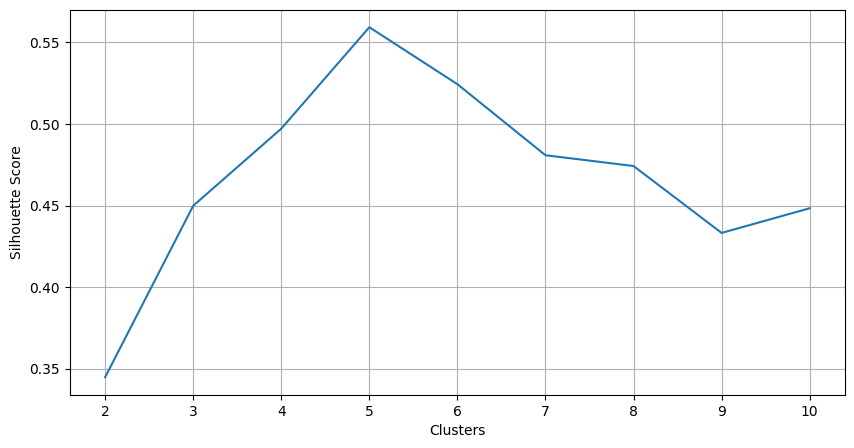

In [35]:
plt.figure(figsize=(10,5))
plt.plot(cluster,sil_score)
plt.xlabel('Clusters')
plt.ylabel('Silhouette Score')
plt.grid()
plt.show()


In silhoutte score we check the peak point is the clusters so k=5 is final

# Task 3 – Hierarchical Clustering

Hierarchical Dendrogram

In [36]:
from scipy.cluster.hierarchy import dendrogram,linkage

In [37]:
Linkage_matrix=linkage(df_2d,method='ward')
print(Linkage_matrix)

[[6.50000000e+01 6.80000000e+01 0.00000000e+00 2.00000000e+00]
 [4.80000000e+01 4.90000000e+01 0.00000000e+00 2.00000000e+00]
 [1.56000000e+02 1.58000000e+02 0.00000000e+00 2.00000000e+00]
 [1.29000000e+02 1.31000000e+02 0.00000000e+00 2.00000000e+00]
 [9.40000000e+01 9.80000000e+01 8.19672131e-03 2.00000000e+00]
 [9.20000000e+01 9.90000000e+01 8.19672131e-03 2.00000000e+00]
 [2.10000000e+01 2.30000000e+01 8.19672131e-03 2.00000000e+00]
 [5.10000000e+01 5.30000000e+01 8.19672131e-03 2.00000000e+00]
 [1.01000000e+02 1.09000000e+02 8.19672131e-03 2.00000000e+00]
 [1.07000000e+02 1.13000000e+02 8.19672131e-03 2.00000000e+00]
 [1.70000000e+02 1.74000000e+02 8.19672131e-03 2.00000000e+00]
 [6.30000000e+01 2.00000000e+02 9.46475851e-03 3.00000000e+00]
 [6.40000000e+01 6.60000000e+01 1.02040816e-02 2.00000000e+00]
 [6.00000000e+01 6.10000000e+01 1.02040816e-02 2.00000000e+00]
 [7.50000000e+01 8.10000000e+01 1.02040816e-02 2.00000000e+00]
 [6.70000000e+01 6.90000000e+01 1.02040816e-02 2.000000

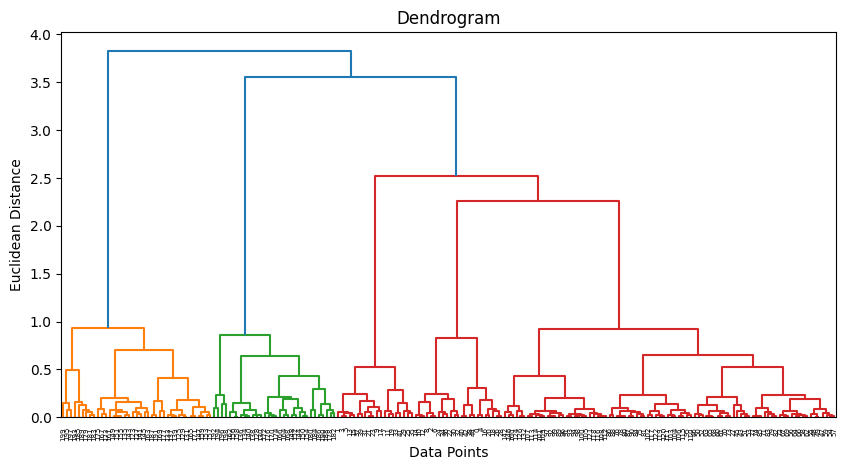

In [41]:
plt.figure(figsize=(10,5))
dendrogram(Linkage_matrix,labels=range(len(df_2d)))
plt.title('Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Euclidean Distance')
plt.show()

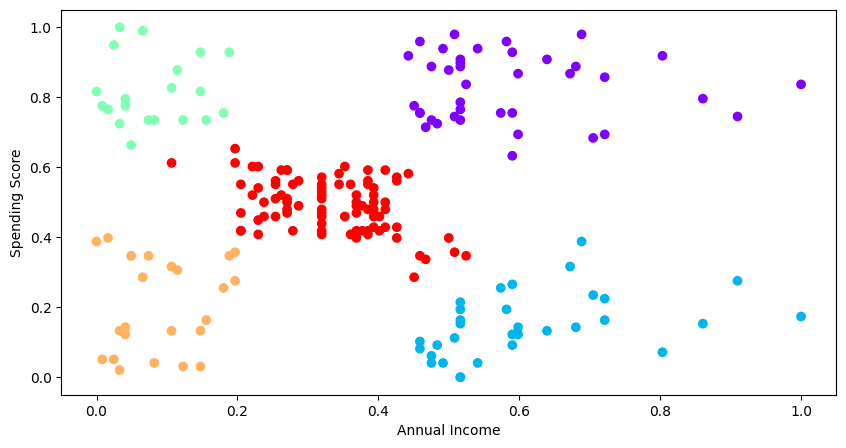

In [57]:
from scipy.cluster.hierarchy import fcluster
cluster=fcluster(Linkage_matrix,t=2,criterion='distance')
plt.figure(figsize=(10,5))
plt.scatter(df_2d['Annual Income'],df_2d['Spending Score'],c=cluster,cmap='rainbow')
plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.show()

In [54]:
print(len(set(cluster)))

5


Dendrogram gives a clusters around 5 Kmeans also give the same

# Task 4 – DBSCAN Clustering

# DBSCAN Clustering

In [95]:
from sklearn.cluster import DBSCAN
dbscan=DBSCAN(eps=0.3,min_samples=3)
dbscan_labels=dbscan.fit_predict(df_scaled)

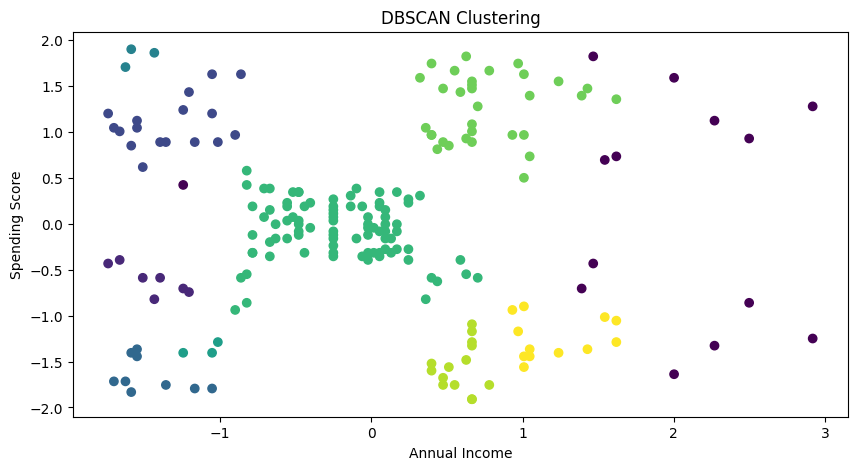

Clusters: 9


In [101]:
plt.figure(figsize=(10,5))
plt.scatter(df_scaled[:,0],df_scaled[:,1],c=dbscan_labels,cmap='viridis')
plt.title('DBSCAN Clustering')
plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.show()
print('Clusters:',len(set(dbscan_labels))-(1 if -1 in dbscan_labels else 0))

DBSCAN gives a clusters around 9 i think it will check the closest point of clusters compare to Kmeans and Hierarchical clustering

In [82]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
df_scaled=scaler.fit_transform(df_2d)

# Task 5 – Dimensionality Reduction

# **PCA Pricipal Compound Interest**

In [113]:
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income', 'Spending Score'], dtype='object')

In [114]:
df_3=df[['CustomerID','Age','Annual Income','Spending Score']]

In [115]:
from sklearn.decomposition import PCA
pca=PCA()
pca.fit(df_3)

PCA()

In [116]:
import numpy as np
cumulative_variance=np.cumsum(pca.explained_variance_ratio_)
print(cumulative_variance)

[0.94498095 0.99998193 0.99999942 1.        ]


In [117]:
n_components=np.argmax(cumulative_variance>=0.95)+1
n_components

np.int64(2)

In [118]:
pcs=PCA(n_components=n_components)
df_pca=pcs.fit_transform(df_3)
print('Original shape:',df_3.shape)
print('Transformed shape:',df_pca.shape)

Original shape: (200, 4)
Transformed shape: (200, 2)


# TSNE Low Dimensionality

In [119]:
from sklearn.manifold import TSNE
tsne=TSNE(n_components=2)
df_tsne=tsne.fit_transform(df_3)
print('Original shape:',df_3.shape)
print('Transformed shape:',df_tsne.shape)

Original shape: (200, 4)
Transformed shape: (200, 2)


Before Reduction

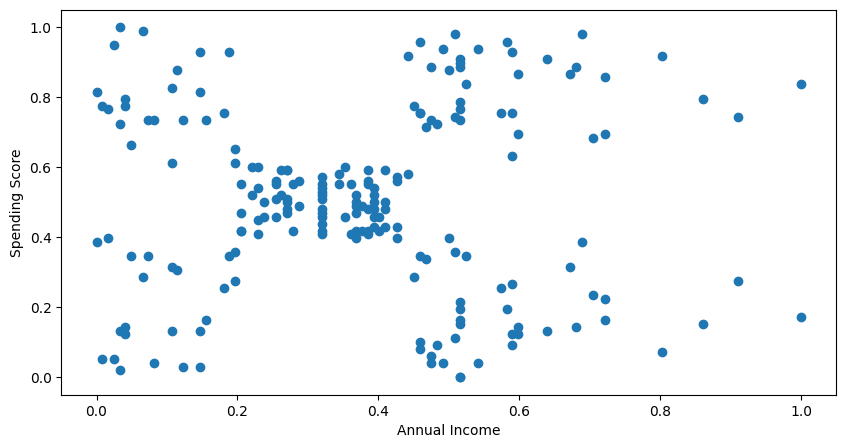

In [123]:
plt.figure(figsize=(10,5))
plt.scatter(df_2d["Annual Income"],df_2d['Spending Score'])
plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.show()

PCA Reduction in features

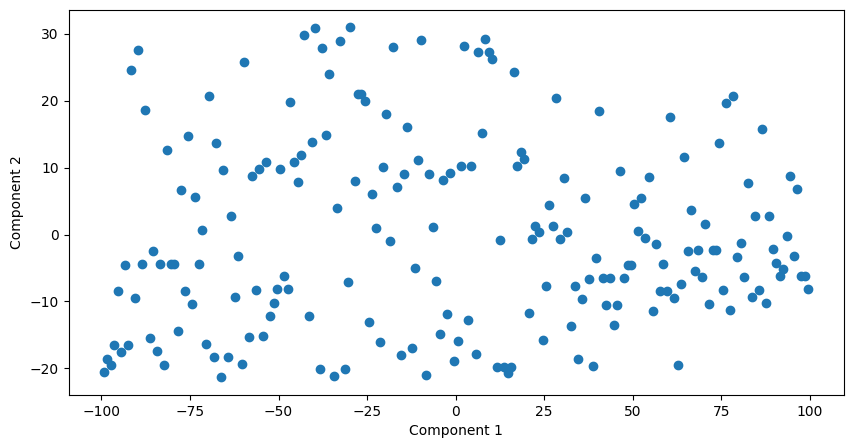

In [121]:
plt.figure(figsize=(10,5))
plt.scatter(df_pca[:,0],df_pca[:,1])
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.show()

TSNE Reduction

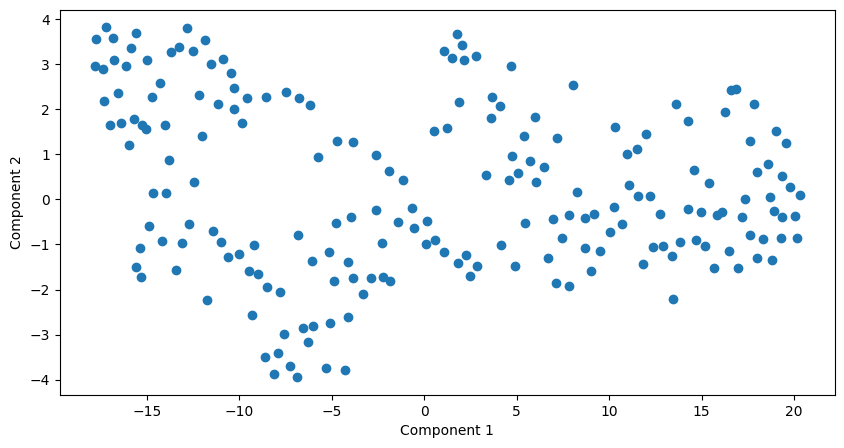

In [120]:
plt.figure(figsize=(10,5))
plt.scatter(df_tsne[:,0],df_tsne[:,1])
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.show()

Overall tsne is the compare to pca its reduce and arrange with best

#Task 6 – Cluster Analysis

In [125]:
"""Task 6 – Cluster Analysis
● Analyze customer characteristics within each cluster
● Identify meaningful customer segments
● Provide business recommendations based on the clusters"""
df_2d['clusters']=dbscan_labels
cluster_analysis=df_2d.groupby('clusters')[['Annual Income','Spending Score']].mean()
cluster_analysis['Customer Count']=df_2d.groupby('clusters').size()

/tmp/ipykernel_694/1971685904.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_2d['clusters']=dbscan_labels


In [126]:
df_2d.head()

,Annual Income,Spending Score,clusters
0,0.000000,0.387755,0
1,0.000000,0.816327,1
2,0.008197,0.051020,2
3,0.008197,0.775510,1
4,0.016393,0.397959,0


In [127]:
cluster_analysis

,Annual Income,Spending Score,Customer Count
clusters,,,
-1,0.766393,0.545918,14
0,0.060890,0.341108,7
1,0.088717,0.787515,17
2,0.059199,0.069161,9
3,0.040984,0.979592,3
4,0.136612,0.142857,3
5,0.328053,0.482917,89
6,0.536885,0.832270,32
7,0.499415,0.092566,14


In cluster analysis i get a clusters and it is final **Clusters=5** because the count is large compare to all

Business recommendation is to maintain all majority of cluster=5 its model to give a meaning ful results